<a href="https://githubtocolab.com/borislevant/python4ml/blob/main/classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>

# SVM

[![scikit-learn logo](./img/scikit-learn-logo-small.png)](https://scikit-learn.org/stable/)


In [1]:
from seaborn import load_dataset
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import make_column_transformer

We already saw (in the Classification notebook) this popular dataset: Palmer Archipelago (Antarctica) penguin dataset appears to be a drop in replacemnt for the same. It is also a great dataset for data exploration & visualization and work on SVM. Let's import the dataset and explore it to understand it better.
source: @allison_horst https://github.com/allisonhorst/penguins

Our goal in this notebook will be to classify the penguins into three types, according to different measurements with SVM.
In this section, you’ll learn how to use Scikit-Learn in Python to build your own support vector machine model. In order to create support vector machine classifiers in sklearn, we can use the SVC class as part of the svm module.

Let’s begin by importing the required libraries for this tutorial:

![](./img/penguins_small.png)


## Understanding the dataset

In [2]:
df = pd.read_csv('./data/penguins_size.csv')
df.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   culmen_length_mm   342 non-null    float64
 3   culmen_depth_mm    342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                334 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


The dataset consists of 7 columns. 

* **species**: penguin species (Chinstrap, Adélie, or Gentoo)
* **culmen_length_mm**: culmen length (mm)
* **culmen_depth_mm**: culmen depth (mm)
* **flipper_length_mm**: flipper length (mm)
* **body_mass_g**: body mass (g)
* **island**: island name (Dream, Torgersen, or Biscoe) in the Palmer Archipelago (Antarctica)
* **sex**: penguin sex

### What are culmen length & depth?
The culmen is "the upper ridge of a bird's beak" 

![](./img/culmen_depth.png)


### What are flippers?
Penguins wings are called flippers. They are flat, thin, and broad with a long, tapered shape and a blunt, rounded tip

![](./img/penguins_body_parts.jpg)

In [4]:
print(df.shape)

(344, 7)


In [5]:
df.describe(include='all')

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
count,344,344,342.000000,342.000000,342.000000,342.000000,334
unique,3,3,NaN,NaN,NaN,NaN,3
top,Adelie,Biscoe,NaN,NaN,NaN,NaN,MALE
freq,152,168,NaN,NaN,NaN,NaN,168
mean,NaN,NaN,43.921930,17.151170,200.915205,4201.754386,NaN
std,NaN,NaN,5.459584,1.974793,14.061714,801.954536,NaN
min,NaN,NaN,32.100000,13.100000,172.000000,2700.000000,NaN
25%,NaN,NaN,39.225000,15.600000,190.000000,3550.000000,NaN
50%,NaN,NaN,44.450000,17.300000,197.000000,4050.000000,NaN
75%,NaN,NaN,48.500000,18.700000,213.000000,4750.000000,NaN


## Missing values

In the previous work on regression we dealt with NaN values by deleting the rows. This time we would like to substitute the values with some estimates. We use the ``SimpleImputer`` class to substitute the *NaN* values. We have a few strategies:

* ``mean`` - replace missing values using the mean along each column. Can only be used with numeric data.
* ``median`` - replace missing values using the median along each column. Can only be used with numeric data.
* ``most_frequent`` - replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.
* ``constant`` - replace missing values with fill_value. Can be used with strings or numeric data.


In [6]:
df.isnull().sum()

species               0
island                0
culmen_length_mm      2
culmen_depth_mm       2
flipper_length_mm     2
body_mass_g           2
sex                  10
dtype: int64

In [7]:
from sklearn.impute import SimpleImputer

#setting strategy to 'most frequent' to impute by the mean
imputer = SimpleImputer(strategy='most_frequent') # strategy can also be mean or median 
df.loc[:, :] = imputer.fit_transform(df)
df.head(5)


,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,41.1,17.0,190.0,3800.0,MALE
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


Another possibility is to use the ``fillna`` function of *Pandas*
``` 
df.fillna( method ='ffill')
```
fills the NaN values with the previous values of the DataFrame


## Cleaning the data

Looking to the unique values of the categorical data we observe strange values that we want to clean before proceed. We first find the column, and decide to substitute the missing value with ``Female`` label

In [8]:
df['sex'].unique()

array(['MALE', 'FEMALE', '.'], dtype=object)

In [9]:
df[df['sex']=='.']

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
336,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,.


In [10]:
df.at[336,'sex'] = 'FEMALE'
df_orig =df

# Scatterplot
The scatter plot which shows us the correlation with respect to other features. This method helps just to figure out the important features which account the most for the classification in our model.

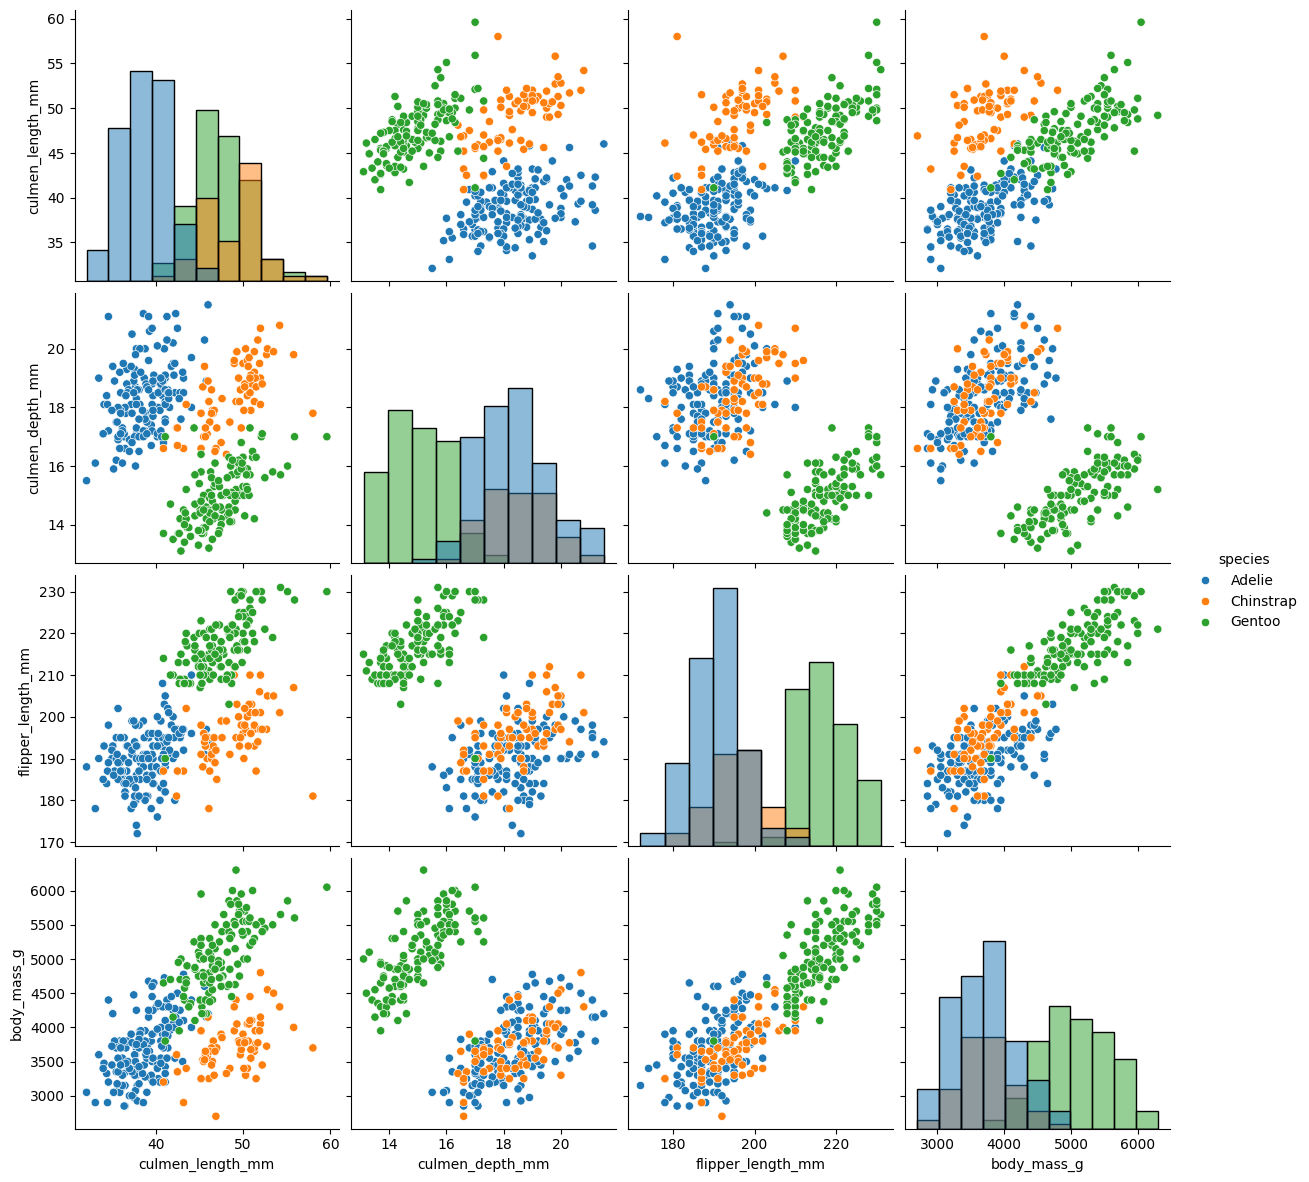

In [11]:
sns.pairplot(df, hue="species", height=3, diag_kind="hist")

## Multi-Class Classification with SVM with Sklearn

Before diving further into building our model, I want to take a moment to discuss how multi-class classification works in SVM. In all the theory covered above we focused on binary classifiers (either “Yes” or “No”, 0 or 1, etc.). As you can see in the data above, there are three classes.
When facing multiple classes, Sklearn applies a one-to-one approach where it models the hyperplane for each pair of potential options. For example, it would build the classifer for Adelie vs. Chinstrap, ignoring Gentoo. Then it would do that same for Adelie vs. Gentoo, ignoring Chinstrap.

In one-to-one multi-class SVM, the class with the most predicted values is the one that’s predicted.

We can determine the number of models that need to be built by using this formula:

In [12]:
num_classes = 4
num_models = (num_classes * (num_classes - 1)) / 2
print(num_models)

6.0


## Splitting our Data into Testing and Training Data

Let’s now split our data into training and testing data. This step is important because it allows us to validate the accuracy of our model against data that the model hasn’t yet seen. For this, we’ll use Sklearn’s train_test_split() function, which I cover in detail here.

To start off with, let’s only look at two numeric variables. We’ll discuss working with categorical data later in the tutorial, but for now let’s ignore those features.

In [13]:
# Splitting our data
X = df[['culmen_length_mm', 'culmen_depth_mm']]
y = df['species']

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=100)


In order to handle classifications, Sklearn provides a support vector machines classifier class called SVC.
The class has a lot of different parameters. In this tutorial, we’ll focus on only a few of them, but set you up to be able to explore the others confidently. In particular, we’ll focus on:

kernel=, which defines what type of function is used to transform the dataset
C=, which defines the regularization of the error.
gamma= defines how loosely the model will fit the training data, allowing you to prevent overfitting
Let’s try building our model first with only the default parameters, except using a linear kernel. Once our model has been set up, we can apply the .train() method to train the data using the X_train and y_train variables:

In [14]:
# Building and training our model
clf = SVC(kernel='linear')
clf.fit(X_train, y_train)
# Making predictions with our data
predictions = clf.predict(X_test)
print(predictions[:5])

# Returns: ['Adelie' 'Chinstrap' 'Adelie' 'Adelie' 'Adelie']

['Gentoo' 'Gentoo' 'Adelie' 'Adelie' 'Gentoo']


You’ve now built your first SVM classifier and made some predictions based on the data!

One of the wonderful things about Scikit-Learn is how much it abstracts what’s going on with the algorithm. This, however, can also be one of the challenges that comes with learning how this actually works. Before diving further into the algorithm, let’s try and visualize what’s gone on here.

We can write some helper code to help us visualize the distribution of the data and plot the linear model that separates the data. Let’s see what this looks like. In order to make this simpler, let’s limit our algorithm to a binary classification.

0.9636363636363636


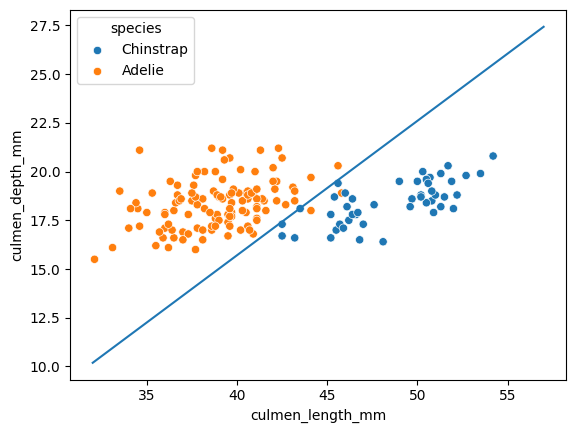

In [15]:
# Rerunning the algorithm with a binary classifier

df = df[df['species'] != 'Gentoo']    # This limits us to two classes


X = df[['culmen_length_mm', 'culmen_depth_mm']]
y = df['species']

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=100)

clf = SVC(kernel='linear')
clf.fit(X_train, y_train)
predictions = clf.predict(X_test)
print(accuracy_score(y_test, predictions))


# Visualizing the linear function for our SVM classifier
import numpy as np
from seaborn import scatterplot

w = clf.coef_[0]
b = clf.intercept_[0]
x_visual = np.linspace(32,57)
y_visual = -(w[0] / w[1]) * x_visual - b / w[1]

scatterplot(data = X_train, x='culmen_length_mm', y='culmen_depth_mm', hue=y_train)
plt.plot(x_visual, y_visual)
plt.show()

We were able to get the coefficient and intercept for our data points and plotted them. One thing you’ll notice is that the data can’t be perfectly separated like our earlier examples. Let’s explore this a little further.

## Soft Margin Classification in Support 
In these cases you, as a data scientist, needs to decide whether to transform the data (and risk overfitting and computational overhead) or whether to soften the margin and allow misclassification of some data.

Softening the margin allows us to find a good balance between keeping a wide margin and limiting the number of margin violations that occur. We’ll explore this a little further when we discuss hyperparameters. For now, it’s important to recognize that by having a harder margin, our data may not generalize to new data as well. By having too soft a margin, our data may not classify well to begin with.

## Testing the Accuracy of our SVM Algorithm
Now that we’ve worked through this aside, lets begin looking at how we can test the accuracy of our model. Since our model aims to classify something, it’s either right or wrong for each data point. Because we already split our data into training and testing data, we can actually run a simple accuracy statistics.

Sklearn comes with a function, accuracy_score(), that calculates the proportion of accurate predictions the model made out of the total number of predictions. Let’s use this function to see how accurate our model is.

We’ll expand the scope to the original intent of the algorithm, to classify all three penguin specifies:

In [16]:
# Testing the accuracy of our model
#df = load_dataset('penguins')
#df = df.dropna()
df= df_orig
X = df[['culmen_length_mm', 'culmen_depth_mm']]
y = df['species']
print(y.unique())

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=100)

clf = SVC(kernel='linear')
clf.fit(X_train, y_train)

predictions = clf.predict(X_test)
print(accuracy_score(y_test, predictions))

# Returns: 0.9761904761904762

['Adelie' 'Chinstrap' 'Gentoo']
0.9767441860465116


## Working with Categorical Data in Support Vector Machines
By their nature, machine learning algorithms cannot work with non-numeric data. This means that when our dataset has features that aren’t numeric, we need to find a way to transform them into types that the algorithm can work with.

One of the most common processes for this is One-Hot Encoding. One-hot encoding takes a categorical feature and converts it into binary columns. Take a look at the image below that illustrates what happens:

![](./img/One-Hot-Encoding.png)

Each unique value in the categorical column is given its own column. If that value matches the column, then it’s assigned a value of 1. Otherwise, it’s assigned a value of 0.

While it may seem more efficient to assign each category a value of, say, [0, 1, 2], this isn’t always a great idea. Unless the ordering of our data has meaning, such as with, say, clothing sizes, this has the potential to misrepresent the distances between our data.

In the same data above, the island Dream isn’t any more different from Torgensen than Biscoe. Because of this one-hot encoding is a safer option for categorical, non-ordinal data.

In order to one-hot encode our data in sklearn, we can make use of the OneHotEncoder class and the make_column_transformer() function. Let’s see how we can one-hot encode our columns, island and sex:


In [17]:
# One-hot encoding categorical variables in Sklearn

X = df.drop(columns = ['species'])
y = df['species']

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state = 100)

column_transformer = make_column_transformer(
    (OneHotEncoder(), ['sex', 'island']),
    remainder='passthrough')

X_train = column_transformer.fit_transform(X_train)
X_train = pd.DataFrame(data=X_train, columns=column_transformer.get_feature_names_out())

Let’s break down what we did here, as we’ve changed some of the lines of code from above:

We loaded the data and dropped missing records
For X, we now load all columns except for the target column, 'species'
We split the data into training and testing data in the same way as before
We then make a new variable, column_transformer that applies the OneHotEncoder class to the sex and island columns.
The remainder= parameter determines what to do with the remaining columns. We’re telling sklearn to simply pass through these.
We fit and transform the X_train data with the .fit_transform() method
Finally, we turn that array back into a Pandas DataFrame

In [18]:
X_train.head()

,onehotencoder__sex_FEMALE,onehotencoder__sex_MALE,onehotencoder__island_Biscoe,onehotencoder__island_Dream,onehotencoder__island_Torgersen,remainder__culmen_length_mm,remainder__culmen_depth_mm,remainder__flipper_length_mm,remainder__body_mass_g
0,1.0,0.0,1.0,0.0,0.0,46.5,13.5,210.0,4550.0
1,1.0,0.0,1.0,0.0,0.0,47.2,15.5,215.0,4975.0
2,0.0,1.0,1.0,0.0,0.0,44.5,14.3,216.0,4100.0
3,1.0,0.0,0.0,1.0,0.0,38.1,18.6,190.0,3700.0
4,0.0,1.0,0.0,0.0,1.0,37.8,17.1,186.0,3300.0


## Standardizing Data for Support Vector Machines
Support vector machines are optimized by the effectiveness of the hyperplane. If our data has different ranges, this can leader to one dimension dominating the others. For example, in our data we now have some binary values (0 or 1) and other data that ranges into the hundreds.

Because the kernel values tend to depend on the dot product of feature vectors, larger ranges can create problems.

In order to circumvent the problem of some dimensions dominating others, we can standardize our data. When we scale our data, the data will have a mean of 0 and a standard deviation of 1.

We can scale our data using the StandardScaler class in sklearn. Because we have already set up a column transformer, we can actually just add this step into it. We’ll apply the transformation to all the numeric columns.

Let’s see how this can work:


In [19]:
# Scaling our data in sklearn
from sklearn.preprocessing import StandardScaler

df = df_orig

X = df.drop(columns = ['species'])
y = df['species']

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state = 100)

column_transformer = make_column_transformer(
    (OneHotEncoder(), ['sex', 'island']),
    (StandardScaler(), ['culmen_depth_mm', 'culmen_length_mm', 'flipper_length_mm', 'body_mass_g']),
    remainder='passthrough')

X_train = column_transformer.fit_transform(X_train)
X_train = pd.DataFrame(data=X_train, columns=column_transformer.get_feature_names_out())

## Hyper-Parameters of the SVM Algorithm in Scikit-Learn
The support vector machine classifier model in sklearn comes with a number of hyper-parameters. In this tutorial, we’ll focus on three main ones:

C=, which defines the regularization of the error.

kernel=, which defines what type of function is used to transform the dataset

gamma= defines how loosely the model will fit the training data, allowing you to prevent overfitting

degree=3,                       # Degree of polynomial function 

Let’s use GridSearch to test this hyper parameters:



In [20]:
from sklearn.model_selection import GridSearchCV
# Finding the best hyperparameters
params = {
    'C': [0.1, 1, 10, 100, 1000],
    'gamma': [1, 0.1, 0.01, 0.001, 0.0001],
    'kernel': ['rbf', 'linear']
}

clf = GridSearchCV(
    estimator=SVC(),
    param_grid=params,
    cv=5,
    verbose=1
)

clf.fit(X_train, y_train)
print(clf.best_params_)

# Returns: {'C': 1000, 'gamma': 0.01, 'kernel': 'rbf'}

Fitting 5 folds for each of 50 candidates, totalling 250 fits
{'C': 0.1, 'gamma': 1, 'kernel': 'linear'}


In this final section, we’ll see what our code looks like now that it’s all come together. The code below cleans up everything we did above and learned about what hyperparameters to apply:

In [21]:
from sklearn.metrics import accuracy_score

# Load the data and create training and testing data
df = df_orig
X = df.drop(columns = ['species'])
y = df['species']

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state = 100)

# Create a transformer object
column_transformer = make_column_transformer(
    (OneHotEncoder(), ['sex', 'island']),
    (StandardScaler(), ['culmen_depth_mm', 'culmen_length_mm', 'flipper_length_mm', 'body_mass_g']),
    remainder='passthrough')

# Transform the training features
X_train = column_transformer.fit_transform(X_train)
print(type(X_train))
print(column_transformer.get_feature_names_out())
X_train = pd.DataFrame(data=X_train, columns=column_transformer.get_feature_names_out())
print(type(X_train))

# Building and fit the classifier
clf = SVC(kernel='rbf', gamma=0.01, C=1000)
clf.fit(X_train, y_train)

# Transform the training data
X_test = column_transformer.transform(X_test)
X_test = pd.DataFrame(data=X_test, columns=column_transformer.get_feature_names_out())

# Make predictions and check the accuracy
predictions = clf.predict(X_test)
print(accuracy_score(y_test, predictions))

# Returns: 0.9880952380952381

<class 'numpy.ndarray'>
['onehotencoder__sex_FEMALE' 'onehotencoder__sex_MALE'
 'onehotencoder__island_Biscoe' 'onehotencoder__island_Dream'
 'onehotencoder__island_Torgersen' 'standardscaler__culmen_depth_mm'
 'standardscaler__culmen_length_mm' 'standardscaler__flipper_length_mm'
 'standardscaler__body_mass_g']
<class 'pandas.core.frame.DataFrame'>
1.0


Now that we have our model, we can actually go one step further. Let’s imagine we have a pet penguin but don’t actually know what species it is. We find our penguin (let’s call her Penny) and take some measurements. We can now take our model to predict Penny’s species. Let’s see how we can do this:

In [22]:
# Passing in our own data:
penny = [{
    'sex': 'FEMALE',
    'island': 'Torgersen', 
    'culmen_depth_mm': 23.3,
    'culmen_length_mm': 43.5,
    'flipper_length_mm': 190, 
    'body_mass_g': 4123
}]

penny = pd.DataFrame(penny)
df_transformed = column_transformer.transform(penny)
df_transformed = pd.DataFrame(df_transformed, columns=column_transformer.get_feature_names_out())
predicted_species = clf.predict(df_transformed)
print(predicted_species)

# Returns: ['Adelie']

['Adelie']


We can be quite confident that Penny is an Adelie penguin!

## Excercise  GridSearchCV for SVM Parameter Tuning (Iris Dataset)
Data: Use the Iris dataset, accessible via datasets.load_iris() from scikit-learn.

Objective: Use GridSearchCV to find the best hyperparameters for an SVM on the Iris dataset.

1.Data Preparation:

Load the Iris dataset.
Split the data into a training set and a test set.

2.GridSearchCV for SVM:

Use GridSearchCV to perform a search over hyperparameter values for an SVM.
Experiment with different values of C (regularization parameter) and gamma (kernel coefficient).
Determine the best combination of hyperparameters.

3.Model Evaluation:

Train an SVM with the best hyperparameters on the training set.
Evaluate the accuracy of the model on the test set.

In [23]:
# Import necessary libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Load the Iris dataset
iris = datasets.load_iris()
X, y = iris.data, iris.target

# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. GridSearchCV for SVM
param_grid = {'C': [0.1, 1, 10, 100], 'gamma': [0.01, 0.1, 1, 10]}
svm = SVC(kernel='rbf')
grid_search = GridSearchCV(svm, param_grid, cv=5)
grid_search.fit(X_train, y_train)

# Get the best hyperparameters
best_params = grid_search.best_params_
best_svm = grid_search.best_estimator_

# 3. Model Evaluation
y_pred = best_svm.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)


# Display results
print("Best Hyperparameters:", best_params)
print("Accuracy on Test Set:", accuracy)


Best Hyperparameters: {'C': 1, 'gamma': 1}
Accuracy on Test Set: 1.0


## Exercice 2 Use the Wine dataset, accessible via datasets.load_wine() from scikit-learn.

Objective: Use an SVM with a polynomial kernel to classify wines into different classes based on their features.

Data Preparation:

Load the Wine dataset.
Split the data into a training set and a test set.
Training a Polynomial SVM:

Use an SVM with a polynomial kernel to train a model on the training set.
Experiment with different degrees of the polynomial kernel.
Evaluate the accuracy of the model on the test set.
Visualization:

Visualize the decision boundary of the polynomial SVM.

In [24]:
# Import necessary libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Load the Wine dataset
wine = datasets.load_wine()
X, y = wine.data, wine.target

# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Training a Polynomial SVM
svm_poly = SVC(kernel='poly', degree=3, C=1)
svm_poly.fit(X_train, y_train)

# 3. Model Evaluation
y_pred_poly = svm_poly.predict(X_test)
accuracy_poly = accuracy_score(y_test, y_pred_poly)

# 4. Visualization
# Visualize the decision boundary for the polynomial SVM
w = clf.dual_coef_[0]
b = clf.intercept_[0]
x_visual = np.linspace(32,57)
y_visual = -(w[0] / w[1]) * x_visual - b / w[1]

# (Visualization code goes here)

# Display results
print("Accuracy on Test Set (Polynomial SVM):", accuracy_poly)


Accuracy on Test Set (Polynomial SVM): 0.8333333333333334


In [25]:
# Import necessary libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Load the Wine dataset
wine = datasets.load_wine()
X, y = wine.data, wine.target

# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# GridSearchCV for SVM with Polynomial Kernel
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': [0.01, 0.1, 1, 10],
    'degree': [2, 3, 4]  # Add the degree parameter for the polynomial kernel
}

svm = SVC(kernel='poly')
grid_search = GridSearchCV(svm, param_grid, cv=5)
grid_search.fit(X_train, y_train)

# Get the best hyperparameters
best_params = grid_search.best_params_
best_svm = grid_search.best_estimator_

# Model Evaluation
y_pred = best_svm.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

# Display results
print("Best Hyperparameters:", best_params)
print("Accuracy on Test Set:", accuracy)


Best Hyperparameters: {'C': 0.1, 'degree': 2, 'gamma': 0.01}
Accuracy on Test Set: 1.0


# References

- Scikit-learn [supervised learning tutorial](http://scikit-learn.org/stable/tutorial/statistical_inference/supervised_learning.html).
- [Tuning meta-parameters](http://scikit-learn.org/stable/modules/grid_search.html#grid-search) with cross validation.
- [One of the best notebooks for ML](https://www.kaggle.com/code/willkoehrsen/start-here-a-gentle-introduction/notebook)

# Futher exercise

- [Regression with a linear model](../exercises/linear-model.ipynb)
- [Classification with a logistic model](../exercises/logistic-tennis.ipynb)